### RaschPy RSM worked example

This notebook works through a sample Rasch analysis of a simulated data set (1,000 persons, 8 items with a maximum score of 5, no missing data), taking you through the relevant commands step by step, with notes before each cell. Relevant outputs will appear below each cell.

Import the modules and set the working directory (here called `my_working_directory`) to where you want to save your output files.

In [1]:
import raschpy as rp
import os

os.chdir('my_working_directory')

**A note on data validation**

Every model constructor validates the item-response network automatically at instantiation (`validate=True` by default) and warns if it's disconnected — if there's no chain of persons and items linking every item to every other, the resulting item locations aren't on a common scale, even though `calibrate()` will still run without error. This is worth seeing happen once. Here we build a small, deliberately disconnected data set: two groups of persons who each only answer a disjoint set of items, with no item shared between the groups to link them:

In [2]:
sim_disconnected = rp.RSM_Sim(no_of_items=8, no_of_persons=80, max_score=4, seed=99)
responses_disconnected = sim_disconnected.responses.copy()
responses_disconnected.iloc[:40, 4:] = float('nan')   # first 40 persons: only answer items 1-4
responses_disconnected.iloc[40:, :4] = float('nan')    # last 40 persons: only answer items 5-8

broken_rsm = rp.RSM(responses_disconnected, max_score=4)   # raises a UserWarning

/Users/markelliott/Documents/RaschPy-dev/raschpy/rsm.py:236: UserWarning: The response data is disconnected into 2 separate sub-networks, with no empirical comparisons spanning them: Sub-group 1 (size 4): ['Item_1', 'Item_2', 'Item_3', 'Item_4']; Sub-group 2 (size 4): ['Item_5', 'Item_6', 'Item_7', 'Item_8']. Items in different sub-networks cannot be placed on a single scale -- each sub-network's estimates are identified only up to its own origin -- and un-smoothed calibration breaks down.
  self.connectivity_status = self.check_data_connectivity()


`connectivity_status` records the diagnosis, including which items ended up in which isolated sub-group:

In [3]:
broken_rsm.connectivity_status

{'connected': False,
 'components_count': 2,
 'isolated_items': [],
 'all_sub_groups': [['Item_1', 'Item_2', 'Item_3', 'Item_4'],
  ['Item_5', 'Item_6', 'Item_7', 'Item_8']],
 'directionally_isolated_items': [],
 'strongly_connected': False}

The rest of this notebook uses a single, fully-connected simulated data set, so this warning won't come up again.

Simulate a data set. Passing `seed=999` makes the simulation fully reproducible — rerunning this notebook will always generate the same data set. 12 items, 1,000 persons, no missing data.

In [4]:
sim = rp.RSM_Sim(no_of_items=12, no_of_persons=500, max_score=5, person_sd=3, missing=0, seed=9999)
sim.responses.to_csv('rsm_scores.csv')

If you have your own response data saved to a CSV file instead of simulating it, use `loadup_rsm()` to load and validate it. Demonstrated here by reloading the file we just saved:

In [5]:
data, invalid_responses = rp.loadup_rsm('rsm_scores.csv', max_score=5)

Check the data - view the first two lines

In [6]:
data.head(2)

,Item_1,Item_2,Item_3,Item_4,Item_5,Item_6,Item_7,Item_8,Item_9,Item_10,Item_11,Item_12
Person,,,,,,,,,,,,
Person_1,2.0,2.0,3.0,2.0,2.0,2.0,3.0,4.0,2.0,2.0,1.0,2.0
Person_2,2.0,2.0,3.0,2.0,3.0,2.0,3.0,3.0,4.0,3.0,3.0,2.0


Check for any invalid responses (not usable for estimation purposes and excluded)

In [7]:
invalid_responses

,Item_1,Item_2,Item_3,Item_4,Item_5,Item_6,Item_7,Item_8,Item_9,Item_10,Item_11,Item_12
Person,,,,,,,,,,,,


Create an RSM object. Passing the simulation object `sim` directly (rather than the reloaded `data`) attaches the generating parameters under `rsm.generating`, which lets us check parameter recovery further down, and also means `max_score` doesn't need to be supplied again. If you're analysing your own data, pass a DataFrame and `max_score` instead (e.g. `rp.RSM(data, max_score)`).

In [8]:
rsm = rp.RSM(sim)

Generate item estimates. The `%%time` "magic function" returns the time taken to run the cell contents (algorithm run time in this case).

To run the analysis using conditional maximum likelihood (CML) estimation (Andersen, 1970), pass `estimation='cml'` to `calibrate()`. The methods that follow use the fit's estimation.

In [9]:
%%time
rsm.calibrate()

CPU times: user 5.17 ms, sys: 532 μs, total: 5.7 ms
Wall time: 5.56 ms


Check the item location estimates

In [10]:
rsm.items

Item_1     1.408257
Item_2     0.550193
Item_3    -0.830137
Item_4     1.308854
Item_5     0.543144
Item_6     0.568101
Item_7    -1.613544
Item_8    -1.311033
Item_9     0.313839
Item_10   -1.457713
Item_11   -0.131036
Item_12    0.651076
dtype: float64

Since this is simulated data, we know the true generating item, threshold and person locations, and can check how closely the calibration recovered them using `recovery_stats()`. This produces a recovery plot per parameter type (generating vs. estimated, with identity/OLS/Huber fit lines) and a summary table (RMSE, MAE, bias, Pearson correlation, SD ratio, OLS/Huber regression slopes, an OLS-vs-Huber divergence flag, and the proportion of parameters flagged as significantly different from their generating value) — for items, thresholds, category widths, and persons all in one call. Person recovery uses a pseudo-estimate construction (Elliott & Buttery, 2022a) rather than comparing directly against the true person location — this isolates estimation/model-specification error from the irreducible noise of a single finite response pattern, which a naive true-vs-estimated comparison would otherwise be dominated by. Results are stored in `rsm.recovery` (e.g. `rsm.recovery.items.summary`, `rsm.recovery.thresholds.summary`, `rsm.recovery.category_widths.summary`, `rsm.recovery.persons.summary`).

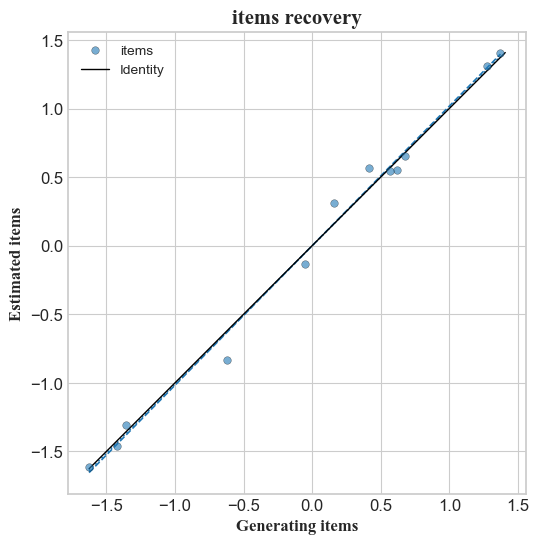

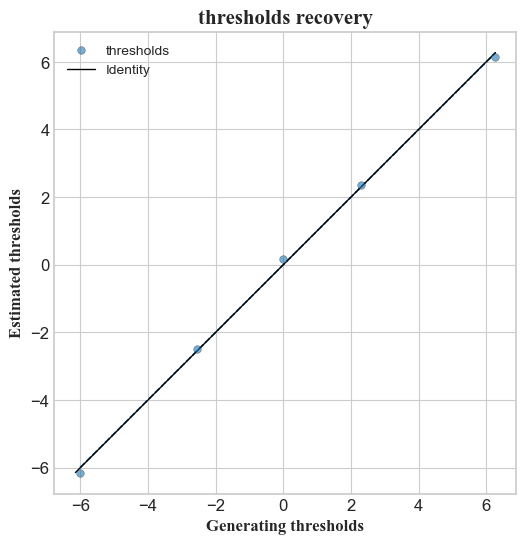

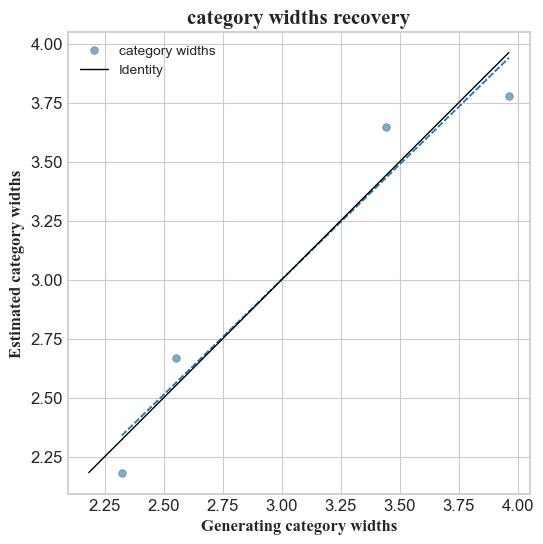

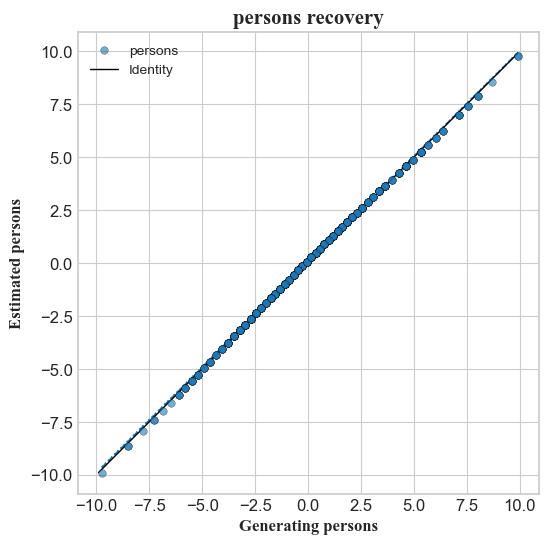

,Overall
RMSE,0.095647
MAE,0.072498
bias,-0.0
r,0.995668
r_squared,0.991356
SD_ratio,1.021711
OLS_slope,1.017286
OLS_intercept,0.0
Huber_slope,1.007807
Huber_intercept,-0.001632


In [11]:
rsm.recovery_stats(filename='my_rsm_recovery')
rsm.recovery.items.summary

Generate a table of item statistics (and check run time), and save to file

In [12]:
%%time
rsm.item_stats_df(full=True, filename='rsm_item_stats')

CPU times: user 1.62 ms, sys: 427 μs, total: 2.05 ms
Wall time: 2.78 ms


,Estimate,SE,2.5%,97.5%,Count,Facility,Infit MS,Infit Z,Outfit MS,Outfit Z,PM corr,Exp PM corr
Item_1,1.408,0.076,1.259,1.558,500,0.406,0.865,-2.181,0.850,-2.317,0.880,0.865
Item_2,0.550,0.072,0.408,0.692,500,0.465,0.885,-1.869,0.862,-2.232,0.882,0.868
Item_3,-0.830,0.080,-0.987,-0.673,500,0.560,1.055,0.881,1.042,0.664,0.857,0.866
Item_4,1.309,0.075,1.161,1.456,500,0.413,0.803,-3.286,0.811,-2.982,0.887,0.865
Item_5,0.543,0.076,0.395,0.691,500,0.464,0.938,-0.969,0.942,-0.897,0.874,0.868
Item_6,0.568,0.077,0.418,0.719,500,0.464,0.990,-0.130,0.987,-0.173,0.868,0.868
Item_7,-1.614,0.081,-1.772,-1.455,500,0.612,0.916,-1.323,0.888,-1.644,0.876,0.861
Item_8,-1.311,0.076,-1.460,-1.162,500,0.593,0.891,-1.761,0.856,-2.228,0.875,0.864
Item_9,0.314,0.072,0.173,0.455,500,0.480,0.856,-2.378,0.828,-2.836,0.887,0.868
Item_10,-1.458,0.075,-1.604,-1.311,500,0.603,0.799,-3.361,0.817,-2.831,0.884,0.863


Check the item statistics table

Generate a table of threshold statistics (and check run time), and save to file

In [13]:
%%time
rsm.threshold_stats_df(full=True, filename='rsm_threshold_stats')

CPU times: user 1.22 ms, sys: 322 μs, total: 1.54 ms
Wall time: 2.91 ms


,Estimate,SE,2.5%,97.5%,Infit MS,Infit Z,Outfit MS,Outfit Z,Discrim,PM corr,Exp PM corr
Threshold 1,-6.146,0.144,-6.428,-5.863,0.944,-1.052,0.780,-1.270,1.057,0.593,0.584
Threshold 2,-2.500,0.075,-2.646,-2.353,0.940,-2.548,0.920,-1.499,1.087,0.831,0.799
Threshold 3,0.168,0.062,0.047,0.289,0.928,-3.542,0.881,-2.708,1.126,0.806,0.760
Threshold 4,2.350,0.077,2.199,2.500,0.939,-2.589,0.883,-2.160,1.099,0.821,0.786
Threshold 5,6.128,0.145,5.843,6.413,0.909,-1.877,0.974,-0.104,1.079,0.699,0.683


Check the threshold statistics table

And the same recovery check for the shared threshold vector (already computed together with item recovery above, via the same `recovery_stats()` call — its plot appeared alongside the item recovery plot):

In [14]:
rsm.recovery.thresholds.summary

,Overall
RMSE,0.125633
MAE,0.114009
bias,0.0
r,0.999548
r_squared,0.999097
SD_ratio,0.998837
OLS_slope,0.998386
OLS_intercept,0.0
Huber_slope,0.998386
Huber_intercept,-0.0


`recovery_stats()` also checks category-width recovery (a separate parameter type from raw threshold locations) as a bonus over the old notebook's checks:

In [15]:
rsm.recovery.category_widths.summary

,Overall
RMSE,0.165229
MAE,0.161354
bias,-0.001023
r,0.969204
r_squared,0.939357
SD_ratio,1.006736
OLS_slope,0.975733
OLS_intercept,0.073463
Huber_slope,0.975724
Huber_intercept,0.073491


Generate a table of person statistics (and check run time), and save to file

In [16]:
%%time
rsm.person_stats_df(full=True, filename='rsm_person_stats')

CPU times: user 3.53 ms, sys: 393 μs, total: 3.92 ms
Wall time: 5.4 ms


,Estimate,CSEM,RSEM,Score,Max score,p,Infit MS,Infit Z,Outfit MS,Outfit Z
Person_1,-0.564,0.463,0.440,27,60,0.450,0.903,-0.111,0.854,-0.240
Person_2,0.482,0.454,0.377,32,60,0.533,0.689,-0.766,0.674,-0.813
Person_3,0.276,0.455,0.477,31,60,0.517,1.097,0.370,1.104,0.386
Person_4,1.720,0.464,0.321,38,60,0.633,0.477,-1.532,0.512,-1.382
Person_5,6.995,0.644,0.579,56,60,0.933,0.809,-0.499,0.650,-0.630
...,...,...,...,...,...,...,...,...,...,...
Person_496,-2.382,0.502,0.618,19,60,0.317,1.517,1.224,1.484,1.163
Person_497,1.936,0.469,0.386,39,60,0.650,0.676,-0.787,0.628,-0.928
Person_498,0.686,0.453,0.532,33,60,0.550,1.375,0.998,1.378,1.005
Person_499,0.276,0.455,0.596,31,60,0.517,1.714,1.623,1.665,1.530


Check the person statistics table - view the first ten persons with `.head(10)`

And the same recovery check for person locations (already computed together with item/threshold recovery above, via the same `recovery_stats()` call — its plot appeared alongside the others):

In [17]:
rsm.recovery.persons.summary

,Overall
RMSE,0.09572
MAE,0.088659
bias,0.053819
r,0.999682
r_squared,0.999365
SD_ratio,0.997269
OLS_slope,0.996953
OLS_intercept,0.053861
Huber_slope,0.996153
Huber_intercept,0.070567


Generate a table of test-level statistics (and check run time), and save to file

In [18]:
%%time
rsm.test_stats_df(filename='rsm_test_stats')

CPU times: user 508 μs, sys: 317 μs, total: 825 μs
Wall time: 1.83 ms


,Items,Persons
Mean,0.000,0.067
SD,1.057,3.122
Separation ratio,13.872,6.406
Strata,18.830,8.874
Reliability,0.995,0.976


Check the test statistics table

Run a residual correlation analysis (and check run time), and save relevant output to file

In [19]:
%%time
rsm.res_corr_analysis()
rsm.residual_correlations.to_csv('rsm_residual_correlations.csv')
rsm.loadings.to_csv('rsm_loadings.csv')

CPU times: user 1.35 ms, sys: 475 μs, total: 1.82 ms
Wall time: 3.17 ms


View the table of pairwise standard residual correlations

In [20]:
round(rsm.residual_correlations, 3)

,Item_1,Item_2,Item_3,Item_4,Item_5,Item_6,Item_7,Item_8,Item_9,Item_10,Item_11,Item_12
Item_1,1.000,-0.064,-0.050,-0.121,-0.072,-0.101,-0.017,-0.119,-0.106,-0.071,-0.097,-0.145
Item_2,-0.064,1.000,-0.201,-0.008,-0.163,-0.065,-0.057,-0.038,-0.106,-0.078,-0.044,-0.144
Item_3,-0.050,-0.201,1.000,-0.106,-0.143,-0.069,-0.134,-0.172,0.047,-0.085,-0.175,-0.003
Item_4,-0.121,-0.008,-0.106,1.000,-0.072,-0.134,-0.125,-0.046,-0.083,-0.160,0.001,-0.076
Item_5,-0.072,-0.163,-0.143,-0.072,1.000,-0.114,-0.106,-0.075,-0.072,-0.055,-0.081,-0.056
Item_6,-0.101,-0.065,-0.069,-0.134,-0.114,1.000,-0.074,-0.101,-0.208,-0.049,-0.115,-0.026
Item_7,-0.017,-0.057,-0.134,-0.125,-0.106,-0.074,1.000,-0.041,-0.092,-0.077,-0.168,-0.089
Item_8,-0.119,-0.038,-0.172,-0.046,-0.075,-0.101,-0.041,1.000,-0.050,-0.110,-0.125,-0.094
Item_9,-0.106,-0.106,0.047,-0.083,-0.072,-0.208,-0.092,-0.050,1.000,-0.073,-0.077,-0.153
Item_10,-0.071,-0.078,-0.085,-0.160,-0.055,-0.049,-0.077,-0.110,-0.073,1.000,-0.027,-0.150


View the item loadings on the first principal component of the pairwise standard residual correlations (dimensionality test)

In [21]:
round(rsm.loadings['PC 1'], 3)

Item_1     0.008
Item_2    -0.539
Item_3     0.742
Item_4    -0.226
Item_5     0.025
Item_6     0.038
Item_7    -0.027
Item_8    -0.248
Item_9     0.266
Item_10   -0.100
Item_11   -0.411
Item_12    0.382
Name: PC 1, dtype: float64

Produce an item characteristic curve (item response function) for Item 2, with observed category means plotted and the central item location marked

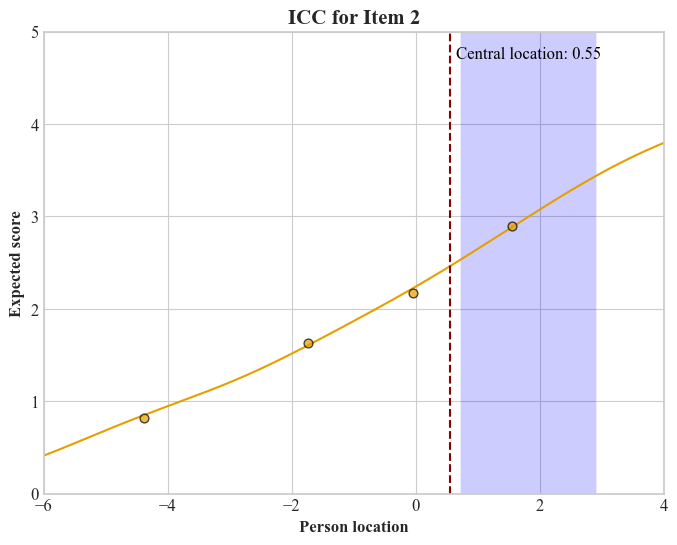

In [22]:
rsm.icc('Item_2', title='ICC for Item 2', obs=True, central_location=True, cat_highlight=3, xmin=-6, xmax=4, filename='my_rsm_icc')

Produce a set of category response curves for Item 2, with category 1 highlighted and the thresholds marked

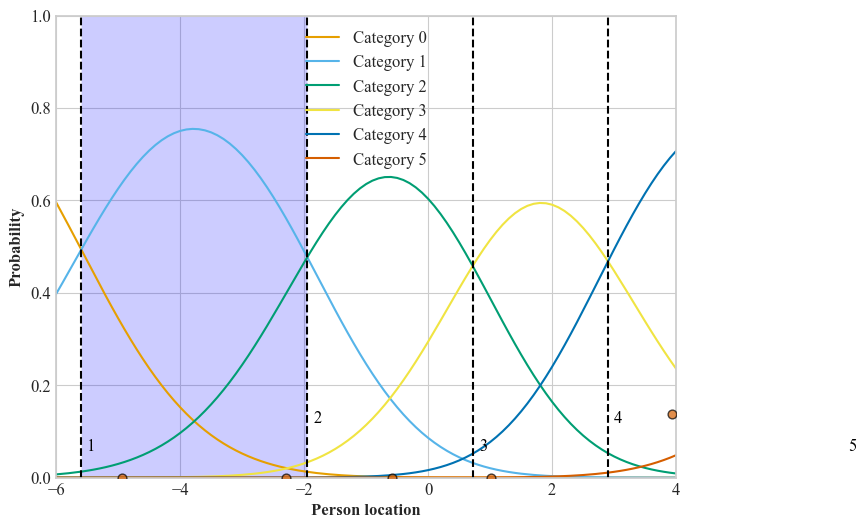

In [23]:
rsm.crcs('Item_2', thresh_lines=True, cat_highlight=1, obs=[5], xmin=-6, xmax=4, filename='my_rsm_crcs')

Produce a set of threshold characteristic curves for Item 2, with observed category means plotted for threshold 5, category 1 highlighted and the thresholds marked

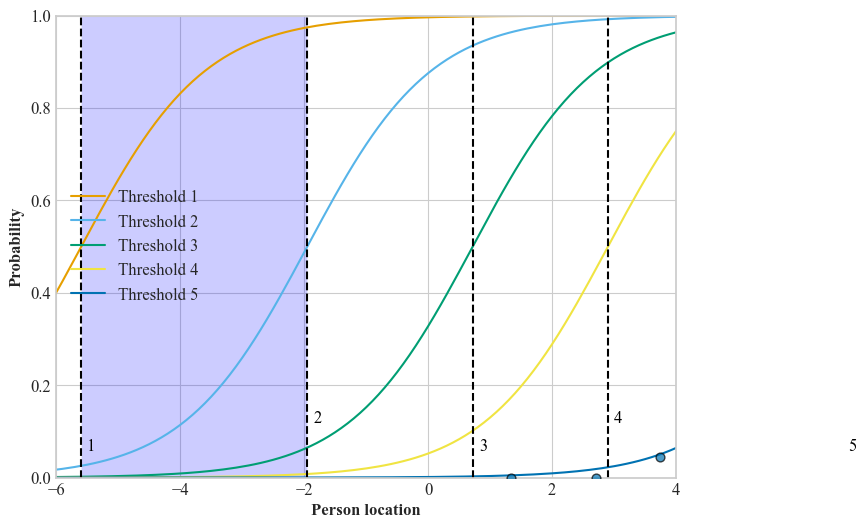

In [24]:
rsm.threshold_ccs('Item_2', thresh_lines=True, obs=[5], cat_highlight=1, xmin=-6, xmax=4, filename='my_rsm_threshold_ccs')

Produce an item information function curve for Item 2

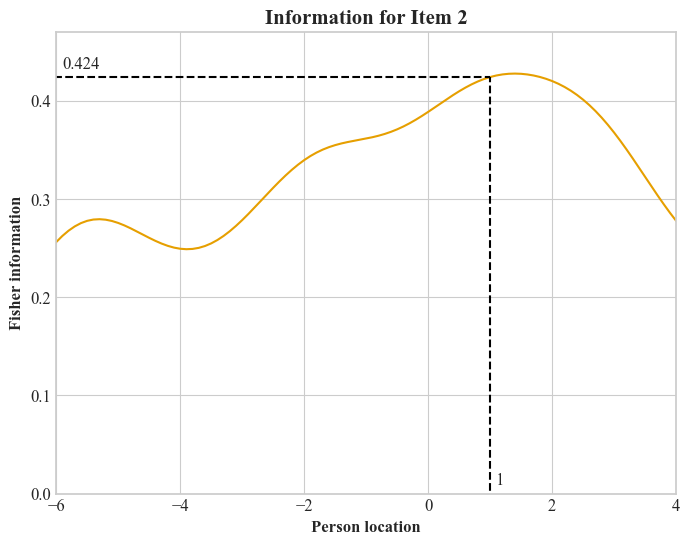

In [25]:
rsm.iic('Item_2', point_info_lines=[1], point_info_labels=True, title='Information for Item 2', xmin=-6, xmax=4, filename='my_rsm_iic')

Produce a test characteristic curve (test response function), with person locations corresponding to scores of 20 and 30 plotted.

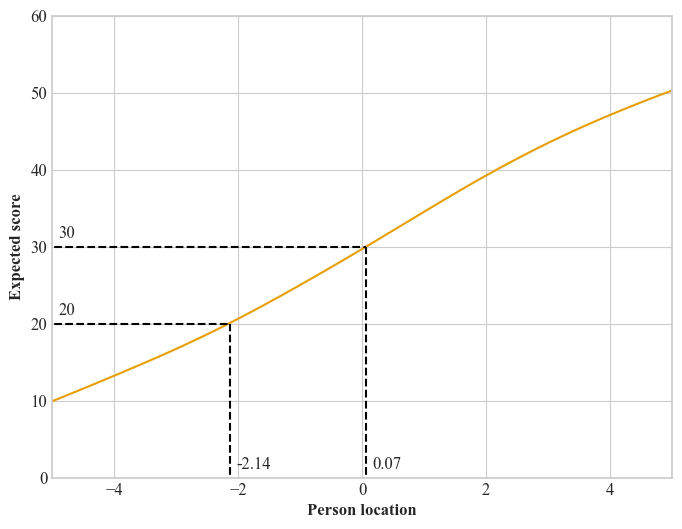

In [26]:
rsm.tcc(score_lines=[20, 30], score_labels=True, filename='my_rsm_tcc')

Produce a test information curve

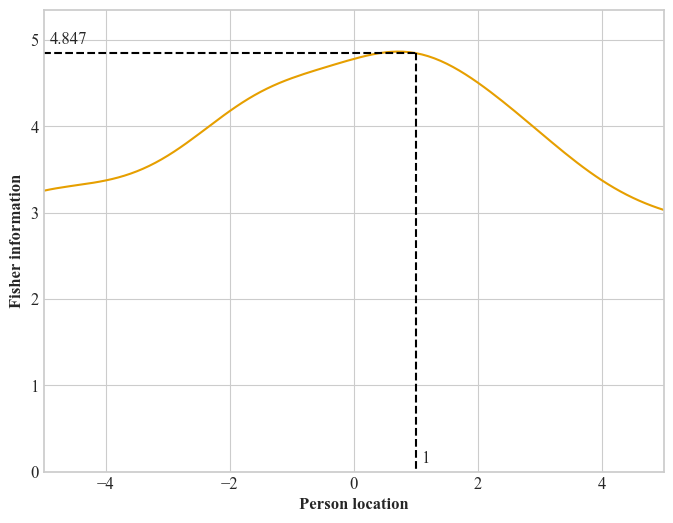

In [27]:
rsm.test_info(point_info_lines=[1], point_info_labels=True, filename='my_rsm_test_info_curve')

Produce a test CSEM (conditional standard error of measurement) curve, with the CSEM corresponding to a person location of -3 plotted

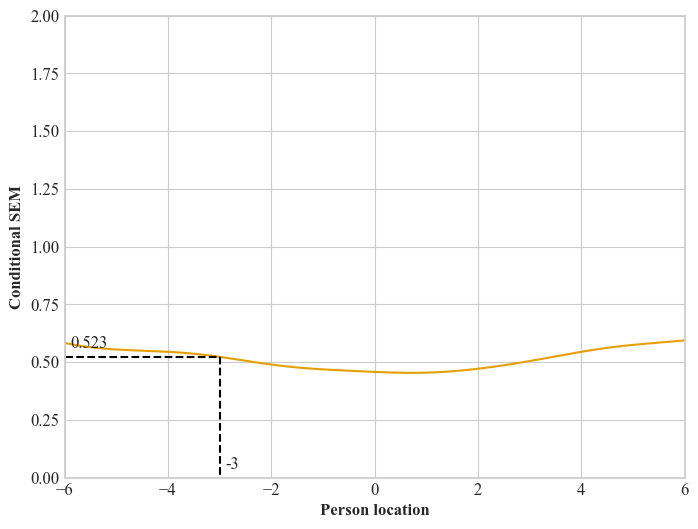

In [28]:
rsm.test_csem(point_csem_lines=[-3], point_csem_labels=True, xmin=-6, xmax=6, ymax=2, filename='my_rsm_csem_curve')

Produce a histogram of standardised residuals, with a normal distribution curve overlaid

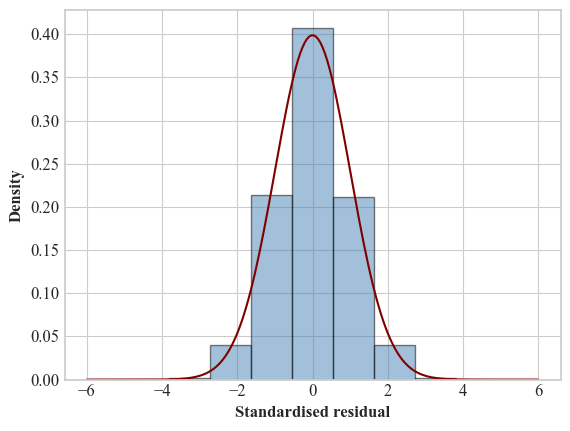

In [29]:
rsm.std_residuals_plot(bin_width=0.6, normal=True, filename='my_rsm_std_residuals_plot')

Produce a Wright map, showing the person location distribution alongside an item strip (one row per item, divided into its own category segments at each Rasch-Andrich threshold), with mean/±1SD/±2SD reference marks for persons

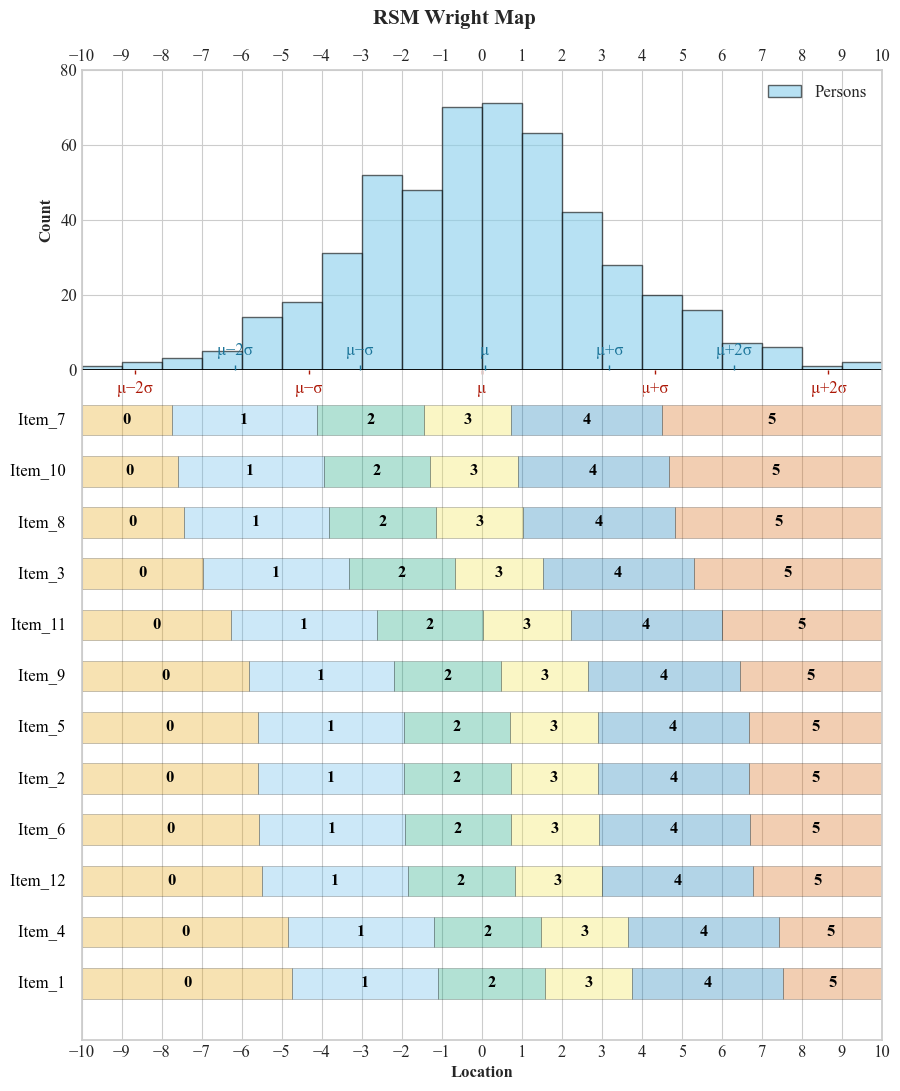

In [30]:
rsm.wright_map(item_strip=True, distribution_markers=True, title='RSM Wright Map', filename='my_rsm_wright_map')

#### References

Andersen, E. B. (1970). Asymptotic properties of conditional maximum-likelihood estimators. *Journal of the Royal Statistical Society, Series B*, 32(2), 283–301.